# **DeiT Art Style Classification**


**🔹 Step 1: Mount Google Drive & Load Dataset**


In [ ]:
from google.colab import drive
drive.mount('/content/drive')  # Correct mount point (not '/content/drive/hyDrive')

Mounted at /content/drive


In [ ]:
!pip install split-folders  # Note: The package name is split-folders (with hyphen)

import os
import splitfolders

# Correct paths (case-sensitive!)
unsplit_path = "/content/drive/MyDrive/artstyleproject/processeddataset_classification2"  # Fixed path
output_path = "/content/processeddataset_classification22"  # Output folder

# Verify the path exists
if not os.path.exists(unsplit_path):
    print(f"Error: Path not found - {unsplit_path}")
    print("Available folders in /content/drive/MyDrive:")
    !ls "/content/drive/MyDrive"
else:
    print("Dataset found successfully!")

Dataset found successfully!


In [ ]:
# Corrected splitfolders call (fixed parameters)
splitfolders.ratio(
    input=unsplit_path,  # Fixed: = instead of -
    output=output_path,  # Fixed: = instead of -
    seed=42,  # Fixed parameter name
    ratio=(0.6, 0.2, 0.2),
    group_prefix=None,
    move=False
)

Copying files: 52094 files [28:53, 30.06 files/s] 


**🔹 Step 1: Install & Import Libraries**

In [ ]:
!pip install timm
!pip install torchvision
!pip install matplotlib
!pip install seaborn
!pip install scikit-learn  # Correct package name instead of 'sklearn'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 32.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.7/188.7 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 76.0 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalli

In [ ]:
import os
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
import timm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc, classification_report
)

In [ ]:
# Define paths (assuming dataset is already split in Colab)
data_dir = "/content/processeddataset_classification22"
train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

# Verify structure
print("Class names:", os.listdir(train_dir))
print("Train samples:", len(os.listdir(os.path.join(train_dir, os.listdir(train_dir)[0]))))
print("Val samples:", len(os.listdir(os.path.join(val_dir, os.listdir(val_dir)[0]))))
print("Test samples:", len(os.listdir(os.path.join(test_dir, os.listdir(test_dir)[0]))))

Class names: ['expressionism', 'baroque', 'romanticism', 'realism', 'impressionism']
Train samples: 6300
Val samples: 2100
Test samples: 2101


**🔹 Step 3: Define Data Transforms & Loaders**

In [ ]:
# DeiT-specific transforms
IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Create datasets
train_dataset = datasets.ImageFolder(train_dir, train_transform)
val_dataset = datasets.ImageFolder(val_dir, val_transform)
test_dataset = datasets.ImageFolder(test_dir, val_transform)

# Create dataloaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

class_names = train_dataset.classes

**🔹 Step 4: Initialize DeiT Model**

In [ ]:
import torch.optim as optim  # Add this import at the top with your other imports

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = timm.create_model('deit_base_patch16_224', pretrained=True, num_classes=len(class_names))
model = model.to(device)

# Loss & optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=3e-5, weight_decay=0.01)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

**🔹 Step 5: Training Loop**

In [ ]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=10):
    train_losses, val_losses = [], []
    train_accs, val_accs = [], []
    start_time = time.time()

    for epoch in range(num_epochs):
        # Training
        model.train()
        epoch_train_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            epoch_train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = epoch_train_loss / len(train_loader)
        train_acc = correct / total
        train_losses.append(train_loss)
        train_accs.append(train_acc)

        # Validation
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        scheduler.step()

        print(f"Epoch {epoch+1}/{num_epochs}")
        print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f} | Acc: {val_acc:.4f}\n")

    training_time = time.time() - start_time
    return model, train_losses, val_losses, train_accs, val_accs, training_time

def evaluate(model, loader, criterion):
    model.eval()
    loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss += criterion(outputs, labels).item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return loss / len(loader), correct / total

# Start training
model, train_losses, val_losses, train_accs, val_accs, training_time = train_model(
    model, criterion, optimizer, scheduler, num_epochs=60
)
print(f"Total training time: {training_time//60:.0f}m {training_time%60:.0f}s")

Epoch 1/60
Train Loss: 0.6063 | Acc: 0.7680
Val Loss: 0.3766 | Acc: 0.8650

Epoch 2/60
Train Loss: 0.2285 | Acc: 0.9231
Val Loss: 0.2164 | Acc: 0.9243

Epoch 3/60
Train Loss: 0.0834 | Acc: 0.9747
Val Loss: 0.1563 | Acc: 0.9491

Epoch 4/60
Train Loss: 0.0363 | Acc: 0.9896
Val Loss: 0.1289 | Acc: 0.9611

Epoch 5/60
Train Loss: 0.0192 | Acc: 0.9948
Val Loss: 0.1140 | Acc: 0.9678

Epoch 6/60
Train Loss: 0.0121 | Acc: 0.9964
Val Loss: 0.1173 | Acc: 0.9679

Epoch 7/60
Train Loss: 0.0055 | Acc: 0.9989
Val Loss: 0.1109 | Acc: 0.9723

Epoch 8/60
Train Loss: 0.0031 | Acc: 0.9992
Val Loss: 0.1134 | Acc: 0.9734

Epoch 9/60
Train Loss: 0.0014 | Acc: 0.9999
Val Loss: 0.1075 | Acc: 0.9750

Epoch 10/60
Train Loss: 0.0010 | Acc: 0.9999
Val Loss: 0.1052 | Acc: 0.9761

Epoch 11/60
Train Loss: 0.0010 | Acc: 1.0000
Val Loss: 0.1052 | Acc: 0.9761

Epoch 12/60
Train Loss: 0.0009 | Acc: 0.9999
Val Loss: 0.1063 | Acc: 0.9763

Epoch 13/60
Train Loss: 0.0008 | Acc: 0.9999
Val Loss: 0.1105 | Acc: 0.9768

Epoch 14

**🔹 Step 6: Evaluation & Metrics**

📊 Evaluation Metrics:
Accuracy: 0.9680
Precision: 0.9679
Recall/Sensitivity: 0.9680
F1-Score: 0.9679
Inference Time per Image: 0.017056s



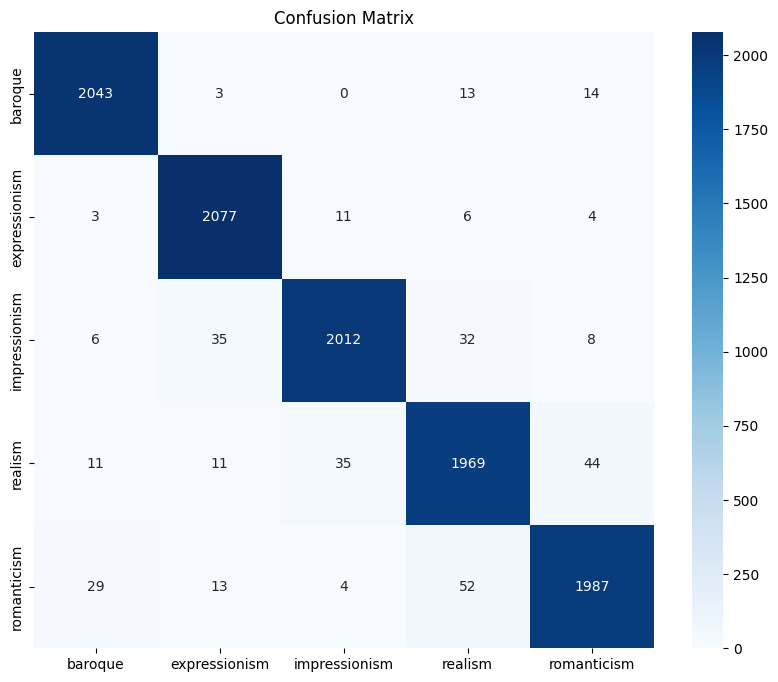

Specificity (baroque): 0.9941
Specificity (expressionism): 0.9925
Specificity (impressionism): 0.9940
Specificity (realism): 0.9877
Specificity (romanticism): 0.9916
Macro-Average Specificity: 0.9920

AUC (baroque): 0.9994
AUC (expressionism): 0.9990
AUC (impressionism): 0.9958
AUC (realism): 0.9957
AUC (romanticism): 0.9967
Macro-Average AUC: 0.9973



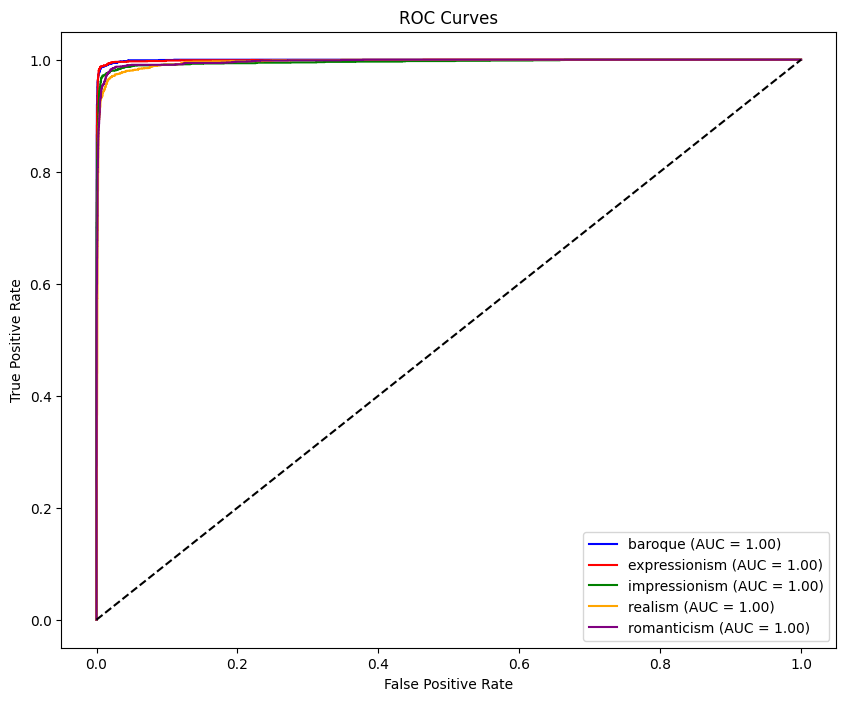

📄 Classification Report:
               precision    recall  f1-score   support

      baroque       0.98      0.99      0.98      2073
expressionism       0.97      0.99      0.98      2101
impressionism       0.98      0.96      0.97      2093
      realism       0.95      0.95      0.95      2070
  romanticism       0.97      0.95      0.96      2085

     accuracy                           0.97     10422
    macro avg       0.97      0.97      0.97     10422
 weighted avg       0.97      0.97      0.97     10422



In [ ]:
def full_evaluation(model, test_loader):
    model.eval()
    all_preds  = []
    all_labels = []
    all_probs  = []
    start_time = time.time()

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            probs   = torch.nn.functional.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    inference_time = (time.time() - start_time) / len(test_loader.dataset)

    # Basic metrics
    accuracy  = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='weighted')
    recall    = recall_score(all_labels, all_preds, average='weighted')  # sensitivity
    f1        = f1_score(all_labels, all_preds, average='weighted')

    print("📊 Evaluation Metrics:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall/Sensitivity: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"Inference Time per Image: {inference_time:.6f}s\n")

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title("Confusion Matrix")
    plt.show()

    # Specificity per class
    specificity = {}
    for i in range(len(class_names)):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        specificity[i] = tn / (tn + fp)
        print(f"Specificity ({class_names[i]}): {specificity[i]:.4f}")
    print(f"Macro-Average Specificity: {np.mean(list(specificity.values())):.4f}\n")

    # ROC & AUC
    fpr     = {}
    tpr     = {}
    roc_auc = {}
    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve((np.array(all_labels)==i).astype(int),
                                      np.array(all_probs)[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        print(f"AUC ({class_names[i]}): {roc_auc[i]:.4f}")
    print(f"Macro-Average AUC: {np.mean(list(roc_auc.values())):.4f}\n")

    # Plot ROC Curves
    plt.figure(figsize=(10, 8))
    colors = ['blue', 'red', 'green', 'orange', 'purple']
    for i, color in zip(range(len(class_names)), colors):
        plt.plot(fpr[i], tpr[i], color=color,
                 label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')
    plt.plot([0,1], [0,1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves')
    plt.legend(loc="lower right")
    plt.show()

    # Classification Report
    print("📄 Classification Report:")
    print(classification_report(all_labels, all_preds, target_names=class_names))


# actually run the evaluation:
full_evaluation(model, test_loader)


**🔹 Step 7: Save Model & Visualizations**

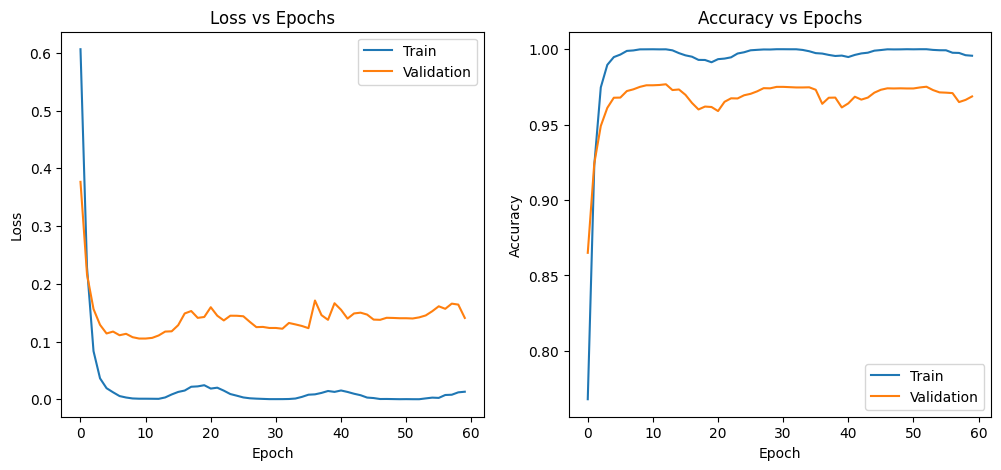

Model saved as deit_art_classifier.pth


In [ ]:
# Loss/Accuracy Curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train')
plt.plot(val_losses, label='Validation')
plt.title('Loss vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train')
plt.plot(val_accs, label='Validation')
plt.title('Accuracy vs Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Save model
torch.save(model.state_dict(), 'deit_art_classifier.pth')
print("Model saved as deit_art_classifier.pth")

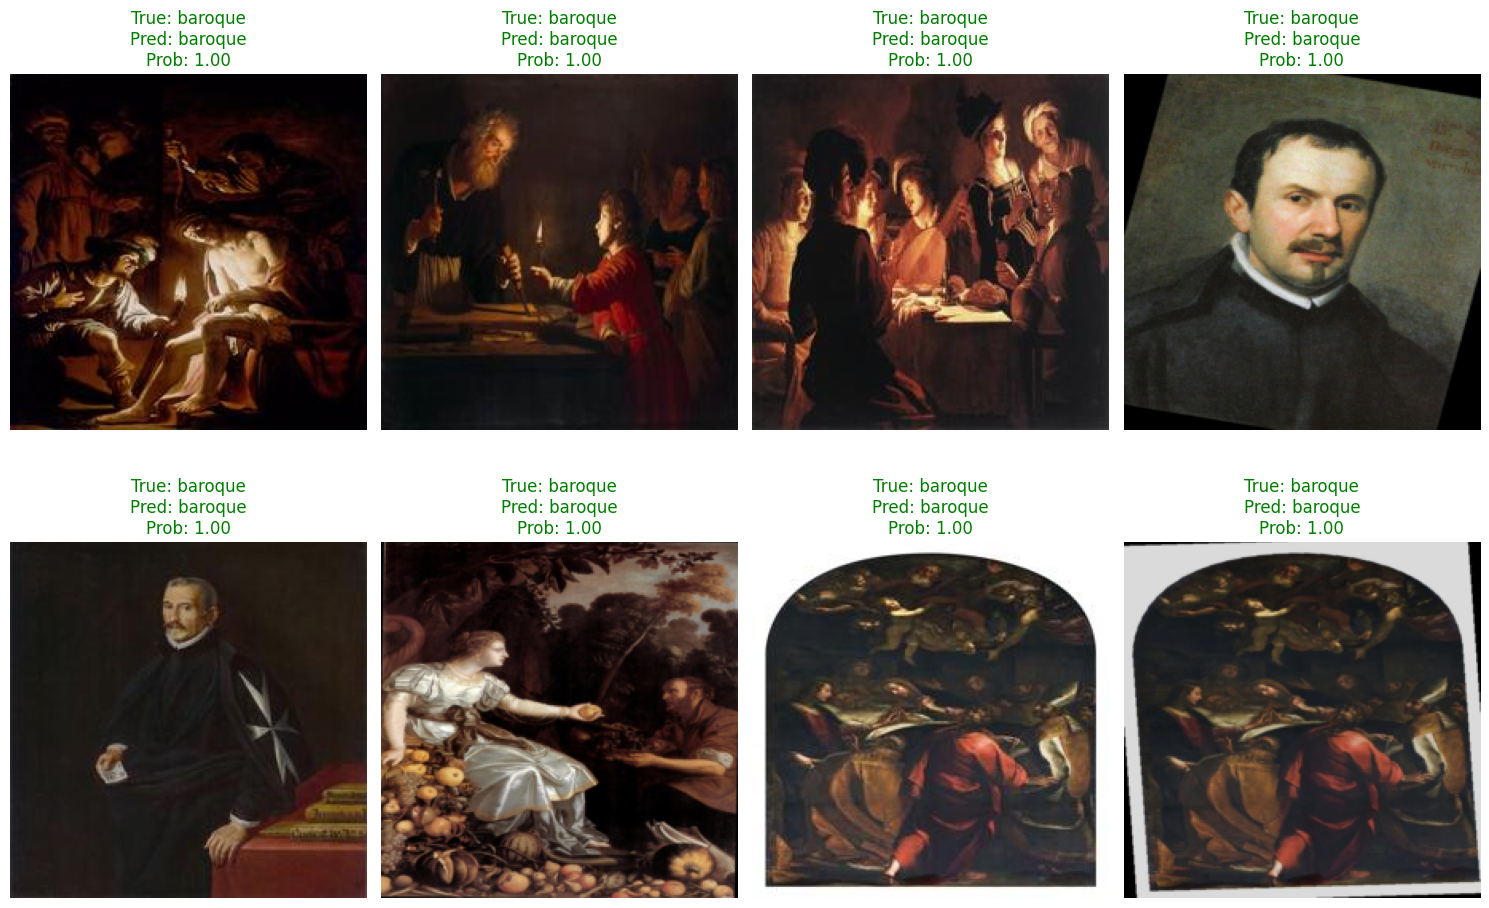

In [ ]:
# Plot sample predictions
def plot_sample_predictions(model, loader, class_names, num_samples=8):
    """
    Plot sample predictions with true vs predicted labels

    Args:
        model: Trained model
        loader: DataLoader for test/validation set
        class_names: List of class names
        num_samples: Number of samples to display (default: 8)
    """
    model.eval()

    # Get a batch of test data
    images, labels = next(iter(loader))
    images = images.to(device)
    labels = labels.to(device)

    # Make predictions
    with torch.no_grad():
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        probs = torch.softmax(outputs, dim=1)

    # Move tensors to CPU
    images = images.cpu()
    labels = labels.cpu()
    preds = preds.cpu()
    probs = probs.cpu()

    # Denormalize images for display
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    images = images * std + mean  # Undo normalization
    images = torch.clamp(images, 0, 1)  # Clip to valid image range

    # Create plot
    plt.figure(figsize=(15, 10))
    for i in range(num_samples):
        plt.subplot(2, 4, i+1)
        img = images[i].permute(1, 2, 0).numpy()

        plt.imshow(img)
        true_label = class_names[labels[i]]
        pred_label = class_names[preds[i]]
        prob = probs[i][preds[i]].item()

        title = f'True: {true_label}\nPred: {pred_label}\nProb: {prob:.2f}'
        if pred_label == true_label:
            plt.title(title, color='green')
        else:
            plt.title(title, color='red')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Call the function with our trained model and test data
plot_sample_predictions(model, test_loader, class_names)